In [2]:
import pandas as pd
import numpy as np

features = pd.read_csv("features.csv")
labels = pd.read_csv("labels.csv")


In [3]:
print("Features shape:", features.shape)
print("Labels shape:", labels.shape)

Features shape: (26707, 36)
Labels shape: (26707, 3)


In [4]:
features.head()

,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,hhs_geo_region,census_msa,household_adults,household_children,employment_industry,employment_occupation
0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,Below Poverty,Not Married,Own,Not in Labor Force,oxchjgsf,Non-MSA,0.0,0.0,NaN,NaN
1,1,3.0,2.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Employed,bhuqouqj,"MSA, Not Principle City",0.0,0.0,pxcmvdjn,xgwztkwe
2,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Own,Employed,qufhixun,"MSA, Not Principle City",2.0,0.0,rucpziij,xtkaffoo
3,3,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,lrircsnp,"MSA, Principle City",0.0,0.0,NaN,NaN
4,4,2.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,qufhixun,"MSA, Not Principle City",1.0,0.0,wxleyezf,emcorrxb


In [5]:
labels.head()

,respondent_id,h1n1_vaccine,seasonal_vaccine
0,0,0,0
1,1,0,1
2,2,0,0
3,3,0,1
4,4,0,0


In [6]:
print("FEATURE COLUMNS:")
print(features.columns.tolist())

print("\nLABEL COLUMNS:")
print(labels.columns.tolist())

FEATURE COLUMNS:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'doctor_recc_seasonal', 'chronic_med_condition', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'opinion_seas_vacc_effective', 'opinion_seas_risk', 'opinion_seas_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'hhs_geo_region', 'census_msa', 'household_adults', 'household_children', 'employment_industry', 'employment_occupation']

LABEL COLUMNS:
['respondent_id', 'h1n1_vaccine', 'seasonal_vaccine']


In [7]:
features.isnull().sum().sort_values(ascending=False)

employment_occupation          13470
employment_industry            13330
health_insurance               12274
income_poverty                  4423
doctor_recc_seasonal            2160
doctor_recc_h1n1                2160
rent_or_own                     2042
employment_status               1463
marital_status                  1408
education                       1407
chronic_med_condition            971
child_under_6_months             820
health_worker                    804
opinion_seas_sick_from_vacc      537
opinion_seas_risk                514
opinion_seas_vacc_effective      462
opinion_h1n1_sick_from_vacc      395
opinion_h1n1_vacc_effective      391
opinion_h1n1_risk                388
household_children               249
household_adults                 249
behavioral_avoidance             208
behavioral_touch_face            128
h1n1_knowledge                   116
h1n1_concern                      92
behavioral_large_gatherings       87
behavioral_outside_home           82
b

In [8]:
print(labels["h1n1_vaccine"].value_counts())
print()
print(labels["seasonal_vaccine"].value_counts())

h1n1_vaccine
0    21033
1     5674
Name: count, dtype: int64

seasonal_vaccine
0    14272
1    12435
Name: count, dtype: int64


In [9]:
print(
    labels["h1n1_vaccine"].value_counts(normalize=True) * 100
)

print(
    labels["seasonal_vaccine"].value_counts(normalize=True) * 100
)

h1n1_vaccine
0    78.754634
1    21.245366
Name: proportion, dtype: float64
seasonal_vaccine
0    53.439173
1    46.560827
Name: proportion, dtype: float64


In [10]:
print("Numerical columns:")
print(features.select_dtypes(include=["int64", "float64"]).columns.tolist())

print("\nCategorical columns:")
print(features.select_dtypes(include=["object"]).columns.tolist())

# 1. Datatypes
print(features.dtypes)


Numerical columns:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'doctor_recc_seasonal', 'chronic_med_condition', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'opinion_seas_vacc_effective', 'opinion_seas_risk', 'opinion_seas_sick_from_vacc', 'household_adults', 'household_children']

Categorical columns:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'hhs_geo_region', 'census_msa', 'employment_industry', 'employment_occupation']
respondent_id                    int64
h1n1_concern                   float64
h1n1_knowledge                 float64
behavioral_antiviral_meds      float64
behavioral_avoidance           flo

/tmp/ipykernel_6632/2428987880.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(features.select_dtypes(include=["object"]).columns.tolist())


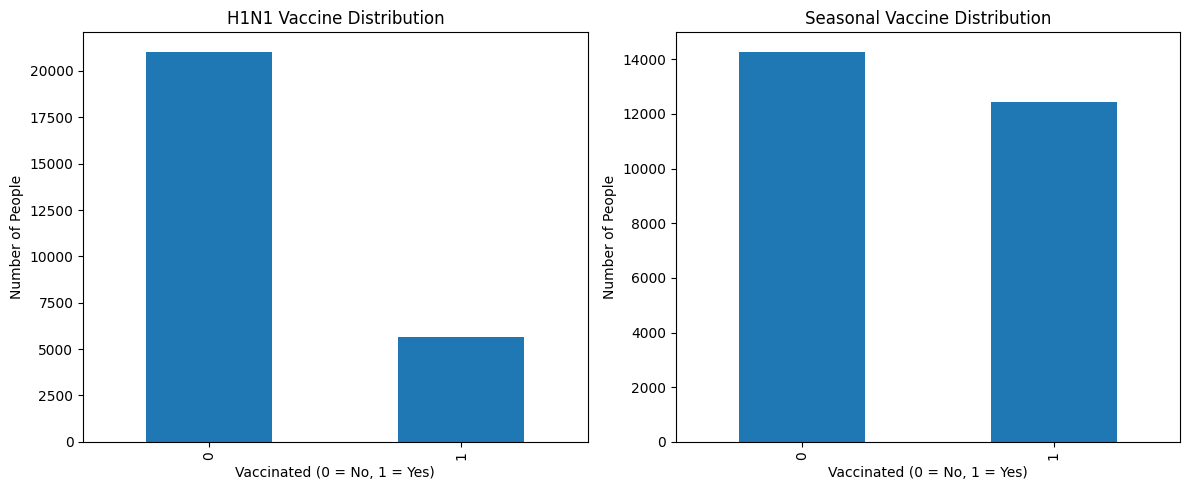

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels["h1n1_vaccine"].value_counts().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("H1N1 Vaccine Distribution")
axes[0].set_xlabel("Vaccinated (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of People")

labels["seasonal_vaccine"].value_counts().plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Seasonal Vaccine Distribution")
axes[1].set_xlabel("Vaccinated (0 = No, 1 = Yes)")
axes[1].set_ylabel("Number of People")

plt.tight_layout()
plt.show()

In [12]:
analysis = labels.copy()

analysis["vaccination_group"] = (
    analysis["h1n1_vaccine"].astype(str)
    + "_"
    + analysis["seasonal_vaccine"].astype(str)
)

analysis["vaccination_group"].value_counts()

vaccination_group
0_0    13295
0_1     7738
1_1     4697
1_0      977
Name: count, dtype: int64

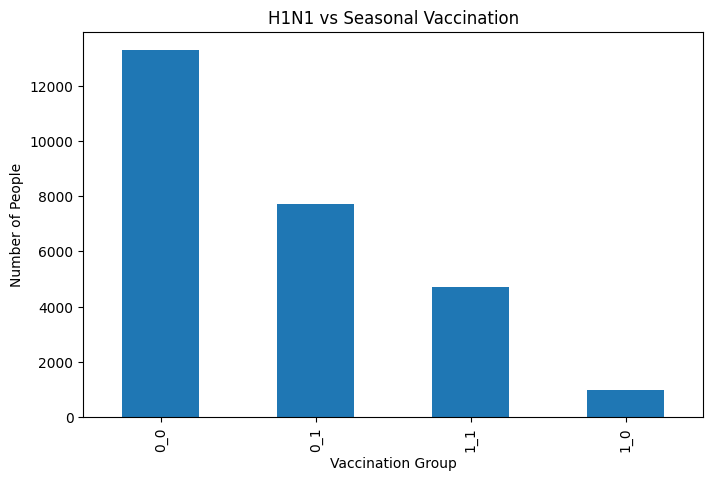

In [13]:
analysis["vaccination_group"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("H1N1 vs Seasonal Vaccination")
plt.xlabel("Vaccination Group")
plt.ylabel("Number of People")
plt.show()

In [14]:
labels[["h1n1_vaccine", "seasonal_vaccine"]].corr()

,h1n1_vaccine,seasonal_vaccine
h1n1_vaccine,1.000000,0.377143
seasonal_vaccine,0.377143,1.000000


In [15]:
temp = pd.concat([features, labels], axis=1)

print(
    pd.crosstab(
        temp["doctor_recc_h1n1"],
        temp["h1n1_vaccine"],
        normalize="index"
    ) * 100
)

print(
    pd.crosstab(
        temp["doctor_recc_seasonal"],
        temp["seasonal_vaccine"],
        normalize="index"
    ) * 100
)

h1n1_vaccine              0          1
doctor_recc_h1n1                      
0.0               86.362924  13.637076
1.0               46.764053  53.235947
seasonal_vaccine              0          1
doctor_recc_seasonal                      
0.0                   65.374096  34.625904
1.0                   26.155177  73.844823


In [16]:
age_analysis = pd.crosstab(
    features["age_group"],
    labels["h1n1_vaccine"],
    normalize="index"
) * 100

print(age_analysis)

seasonal_age_analysis = pd.crosstab(
    features["age_group"],
    labels["seasonal_vaccine"],
    normalize="index"
) * 100

print(seasonal_age_analysis)

h1n1_vaccine           0          1
age_group                          
18 - 34 Years  80.997124  19.002876
35 - 44 Years  80.223493  19.776507
45 - 54 Years  80.526919  19.473081
55 - 64 Years  75.714543  24.285457
65+ Years      77.334502  22.665498
seasonal_vaccine          0          1
age_group                             
18 - 34 Years     71.543624  28.456376
35 - 44 Years     63.747401  36.252599
45 - 54 Years     59.870179  40.129821
55 - 64 Years     48.876505  51.123495
65+ Years         32.631887  67.368113


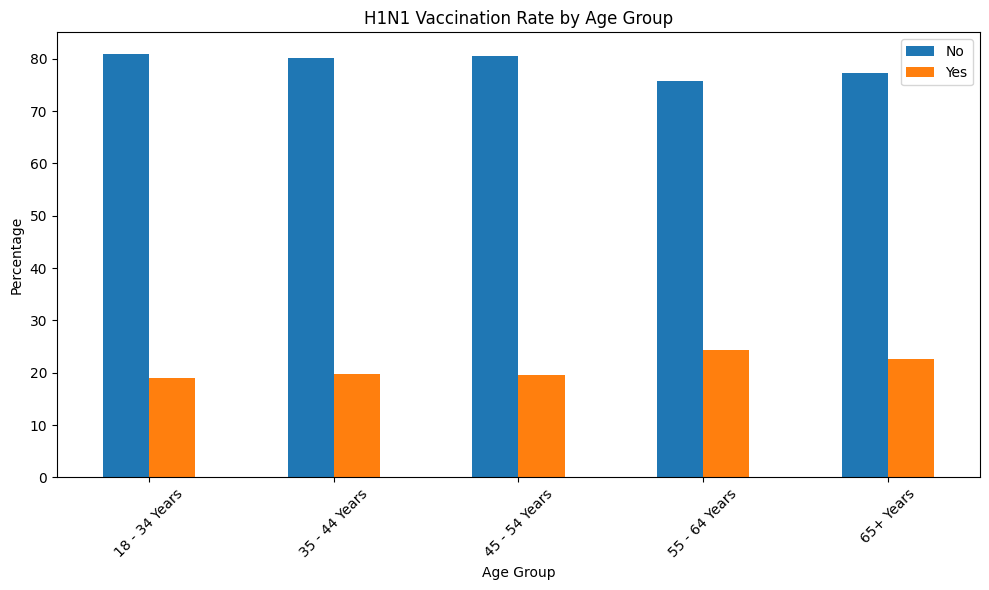

In [17]:
age_analysis.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("H1N1 Vaccination Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend(["No", "Yes"])
plt.tight_layout()
plt.show()

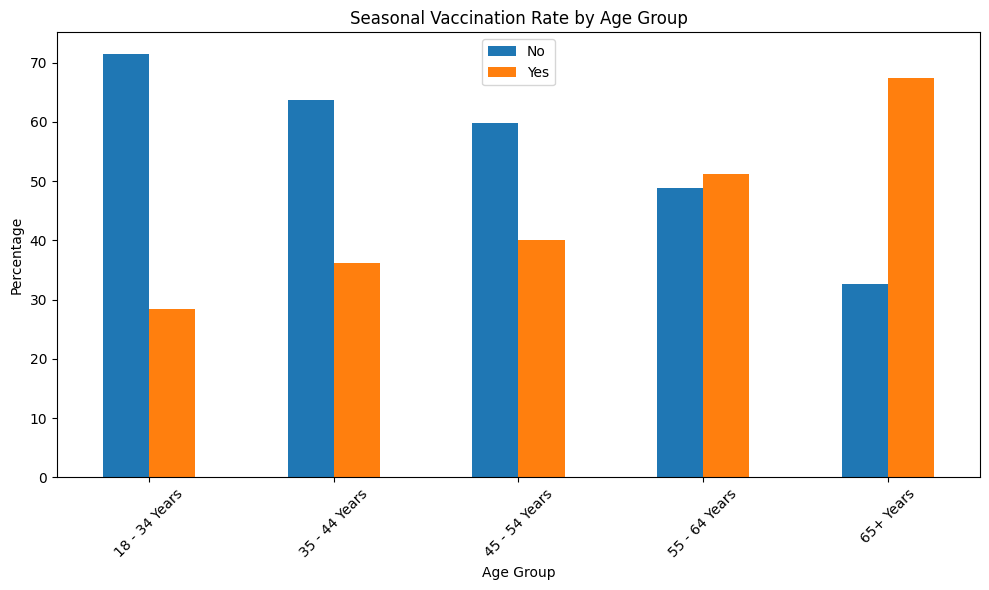

In [18]:
seasonal_age_analysis.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Seasonal Vaccination Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend(["No", "Yes"])
plt.tight_layout()
plt.show()

In [19]:
insurance_h1n1 = pd.crosstab(
    features["health_insurance"],
    labels["h1n1_vaccine"],
    normalize="index"
) * 100

print("H1N1 vaccination:")
print(insurance_h1n1)

H1N1 vaccination:
h1n1_vaccine              0          1
health_insurance                      
0.0               85.253456  14.746544
1.0               68.228715  31.771285


In [20]:
insurance_seasonal = pd.crosstab(
    features["health_insurance"],
    labels["seasonal_vaccine"],
    normalize="index"
) * 100

print("\nSeasonal vaccination:")
print(insurance_seasonal)


Seasonal vaccination:
seasonal_vaccine          0          1
health_insurance                      
0.0               77.073733  22.926267
1.0               46.199890  53.800110


In [21]:
chronic_h1n1 = pd.crosstab(
    features["chronic_med_condition"],
    labels["h1n1_vaccine"],
    normalize="index"
) * 100

print("H1N1 vaccination:")
print(chronic_h1n1)

H1N1 vaccination:
h1n1_vaccine                   0          1
chronic_med_condition                      
0.0                    81.112436  18.887564
1.0                    72.455418  27.544582


In [22]:
chronic_seasonal = pd.crosstab(
    features["chronic_med_condition"],
    labels["seasonal_vaccine"],
    normalize="index"
) * 100

print("\nSeasonal vaccination:")
print(chronic_seasonal)


Seasonal vaccination:
seasonal_vaccine               0          1
chronic_med_condition                      
0.0                    58.489645  41.510355
1.0                    39.643347  60.356653


In [23]:
concern_h1n1 = pd.crosstab(
    features["h1n1_concern"],
    labels["h1n1_vaccine"],
    normalize="index"
) * 100

print("H1N1 vaccination by concern:")
print(concern_h1n1)

H1N1 vaccination by concern:
h1n1_vaccine          0          1
h1n1_concern                      
0.0           86.438107  13.561893
1.0           82.865203  17.134797
2.0           76.614657  23.385343
3.0           70.790677  29.209323


In [24]:
knowledge_h1n1 = pd.crosstab(
    features["h1n1_knowledge"],
    labels["h1n1_vaccine"],
    normalize="index"
) * 100

print("\nH1N1 vaccination by knowledge:")
print(knowledge_h1n1)


H1N1 vaccination by knowledge:
h1n1_vaccine            0          1
h1n1_knowledge                      
0.0             85.594573  14.405427
1.0             81.826278  18.173722
2.0             72.193528  27.806472


In [25]:
for col in [
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "opinion_h1n1_sick_from_vacc"
]:
    result = pd.crosstab(
        features[col],
        labels["h1n1_vaccine"],
        normalize="index"
    ) * 100
    
    print(f"\n{col}")
    print(result)


opinion_h1n1_vacc_effective
h1n1_vaccine                         0          1
opinion_h1n1_vacc_effective                      
1.0                          95.259594   4.740406
2.0                          94.886975   5.113025
3.0                          89.434681  10.565319
4.0                          82.358983  17.641017
5.0                          59.517164  40.482836

opinion_h1n1_risk
h1n1_vaccine               0          1
opinion_h1n1_risk                      
1.0                91.165991   8.834009
2.0                83.203952  16.796048
3.0                82.632050  17.367950
4.0                60.789766  39.210234
5.0                48.914286  51.085714

opinion_h1n1_sick_from_vacc
h1n1_vaccine                         0          1
opinion_h1n1_sick_from_vacc                      
1.0                          79.539898  20.460102
2.0                          82.681564  17.318436
3.0                          91.891892   8.108108
4.0                          73.572650  26.

In [26]:
for col in [
    "opinion_seas_vacc_effective",
    "opinion_seas_risk",
    "opinion_seas_sick_from_vacc"
]:
    result = pd.crosstab(
        features[col],
        labels["seasonal_vaccine"],
        normalize="index"
    ) * 100
    
    print(f"\n{col}")
    print(result)


opinion_seas_vacc_effective
seasonal_vaccine                     0          1
opinion_seas_vacc_effective                      
1.0                          84.193284  15.806716
2.0                          85.448776  14.551224
3.0                          72.039474  27.960526
4.0                          62.369937  37.630063
5.0                          29.529730  70.470270

opinion_seas_risk
seasonal_vaccine           0          1
opinion_seas_risk                      
1.0                79.059257  20.940743
2.0                62.687067  37.312933
3.0                44.313146  55.686854
4.0                33.656619  66.343381
5.0                25.524003  74.475997

opinion_seas_sick_from_vacc
seasonal_vaccine                     0          1
opinion_seas_sick_from_vacc                      
1.0                          48.711036  51.288964
2.0                          57.526530  42.473470
3.0                          81.914894  18.085106
4.0                          54.039571  45.

In [27]:
labels[["h1n1_vaccine", "seasonal_vaccine"]].corr()

,h1n1_vaccine,seasonal_vaccine
h1n1_vaccine,1.000000,0.377143
seasonal_vaccine,0.377143,1.000000


In [28]:
analysis = labels.copy()

analysis["vaccination_group"] = (
    analysis["h1n1_vaccine"].astype(str) + "_" +
    analysis["seasonal_vaccine"].astype(str)
)

print(analysis["vaccination_group"].value_counts())

vaccination_group
0_0    13295
0_1     7738
1_1     4697
1_0      977
Name: count, dtype: int64


In [29]:
X = features.drop(columns=["respondent_id"])

y_h1n1 = labels["h1n1_vaccine"]
y_seasonal = labels["seasonal_vaccine"]

print("X shape:", X.shape)
print("H1N1 shape:", y_h1n1.shape)
print("Seasonal shape:", y_seasonal.shape)

X shape: (26707, 35)
H1N1 shape: (26707,)
Seasonal shape: (26707,)


In [30]:
from sklearn.model_selection import train_test_split

stratify_group = (
    y_h1n1.astype(str) + "_" +
    y_seasonal.astype(str)
)

X_train, X_test, y_h1n1_train, y_h1n1_test, y_seasonal_train, y_seasonal_test = train_test_split(
    X,
    y_h1n1,
    y_seasonal,
    test_size=0.20,
    random_state=42,
    stratify=stratify_group
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 21365
Testing samples: 5342


In [32]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric features:")
print(len(numeric_features))

print("\nCategorical features:")
print(len(categorical_features))

Numeric features:
23

Categorical features:
12


/tmp/ipykernel_6632/1867586014.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

In [34]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [35]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [36]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [38]:
h1n1_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

seasonal_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [40]:
h1n1_model.fit(X_train, y_h1n1_train)

print("H1N1 model trained successfully!")

h1n1_pred = h1n1_model.predict_proba(X_test)[:, 1]

print(h1n1_pred[:10])

H1N1 model trained successfully!
[0.03165176 0.68682205 0.0348785  0.09592692 0.11074059 0.45659483
 0.89936924 0.04778678 0.0825895  0.40719417]


In [42]:
seasonal_model.fit(X_train, y_seasonal_train)

print("Seasonal model trained successfully!")

seasonal_pred = seasonal_model.predict_proba(X_test)[:, 1]

print(seasonal_pred[:10])

Seasonal model trained successfully!
[0.53123971 0.82909421 0.08444355 0.12871938 0.2732827  0.17505059
 0.9827891  0.83341253 0.46289522 0.97845627]


In [44]:
from sklearn.metrics import roc_auc_score
auc_h1n1 = roc_auc_score(
    y_h1n1_test,
    h1n1_pred
)

print("H1N1 ROC-AUC:", auc_h1n1)

H1N1 ROC-AUC: 0.8381621149562981


In [45]:
auc_seasonal = roc_auc_score(
    y_seasonal_test,
    seasonal_pred
)

print("Seasonal ROC-AUC:", auc_seasonal)

Seasonal ROC-AUC: 0.8540243343240266


In [46]:
overall_auc = (auc_h1n1 + auc_seasonal) / 2

print("Overall ROC-AUC:", overall_auc)

Overall ROC-AUC: 0.8460932246401623


In [47]:
feature_names = h1n1_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = h1n1_model.named_steps["classifier"].coef_[0]

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

feature_importance["abs_coefficient"] = (
    feature_importance["coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "abs_coefficient",
    ascending=False
)

print(feature_importance.head(20))

                                feature  coefficient  abs_coefficient
85  cat__employment_occupation_dcjcmpih     1.147911         1.147911
66    cat__employment_industry_haxffmxo     1.147911         1.147911
9                 num__doctor_recc_h1n1     0.812171         0.812171
68    cat__employment_industry_mcubkhph    -0.623280         0.623280
15     num__opinion_h1n1_vacc_effective     0.618131         0.618131
95  cat__employment_occupation_qxajmpny    -0.471226         0.471226
16               num__opinion_h1n1_risk     0.462558         0.462558
99  cat__employment_occupation_uqqtjvyb    -0.437260         0.437260
63    cat__employment_industry_cfqqtusy    -0.425405         0.425405
96  cat__employment_occupation_rcertsgn    -0.411507         0.411507
98  cat__employment_occupation_ukymxvdu     0.341642         0.341642
32                      cat__race_Black    -0.338864         0.338864
36                      cat__sex_Female    -0.301736         0.301736
75    cat__employmen

In [48]:
seasonal_coefficients = seasonal_model.named_steps["classifier"].coef_[0]

seasonal_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": seasonal_coefficients
})

seasonal_importance["abs_coefficient"] = (
    seasonal_importance["coefficient"].abs()
)

seasonal_importance = seasonal_importance.sort_values(
    "abs_coefficient",
    ascending=False
)

print(seasonal_importance.head(20))

                                 feature  coefficient  abs_coefficient
66     cat__employment_industry_haxffmxo     1.534556         1.534556
85   cat__employment_occupation_dcjcmpih     1.534556         1.534556
27              cat__age_group_65+ Years     0.949047         0.949047
19                num__opinion_seas_risk     0.738899         0.738899
10             num__doctor_recc_seasonal     0.655319         0.655319
23          cat__age_group_18 - 34 Years    -0.629116         0.629116
18      num__opinion_seas_vacc_effective     0.616933         0.616933
75     cat__employment_industry_rucpziij    -0.610166         0.610166
95   cat__employment_occupation_qxajmpny    -0.533576         0.533576
76     cat__employment_industry_saaquncn    -0.532879         0.532879
70     cat__employment_industry_msuufmds     0.507728         0.507728
77     cat__employment_industry_vjjrobsf    -0.432136         0.432136
24          cat__age_group_35 - 44 Years    -0.357349         0.357349
68    

In [49]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numeric preprocessing - NO scaling
numeric_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocessor
rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_rf, numeric_features),
        ("cat", categorical_transformer_rf, categorical_features)
    ]
)

In [50]:
rf_h1n1 = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_seasonal = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [51]:
rf_h1n1.fit(X_train, y_h1n1_train)

rf_seasonal.fit(X_train, y_seasonal_train)

print("Random Forest models trained successfully!")

Random Forest models trained successfully!


In [52]:
rf_h1n1_pred = rf_h1n1.predict_proba(X_test)[:, 1]

rf_seasonal_pred = rf_seasonal.predict_proba(X_test)[:, 1]

print("H1N1 predictions:", rf_h1n1_pred[:10])
print("Seasonal predictions:", rf_seasonal_pred[:10])

H1N1 predictions: [0.06  0.775 0.06  0.11  0.075 0.36  0.75  0.08  0.15  0.4  ]
Seasonal predictions: [0.46  0.85  0.08  0.39  0.26  0.37  0.975 0.795 0.465 0.855]


In [53]:
from sklearn.metrics import roc_auc_score

rf_h1n1_auc = roc_auc_score(
    y_h1n1_test,
    rf_h1n1_pred
)

rf_seasonal_auc = roc_auc_score(
    y_seasonal_test,
    rf_seasonal_pred
)

rf_overall_auc = (rf_h1n1_auc + rf_seasonal_auc) / 2

print("Random Forest H1N1 ROC-AUC:", round(rf_h1n1_auc, 3))
print("Random Forest Seasonal ROC-AUC:", round(rf_seasonal_auc, 3))
print("Random Forest Overall ROC-AUC:", round(rf_overall_auc, 3))

Random Forest H1N1 ROC-AUC: 0.833
Random Forest Seasonal ROC-AUC: 0.85
Random Forest Overall ROC-AUC: 0.841


In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

depth_values = [5, 10, 15, 20, None]

rf_depth_results = []

for depth in depth_values:

    model = Pipeline(steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_h1n1_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_h1n1_test, pred)

    rf_depth_results.append((depth, auc))

    print("max_depth:", depth, "H1N1 ROC-AUC:", round(auc, 3))

max_depth: 5 H1N1 ROC-AUC: 0.822
max_depth: 10 H1N1 ROC-AUC: 0.833
max_depth: 15 H1N1 ROC-AUC: 0.836
max_depth: 20 H1N1 ROC-AUC: 0.834
max_depth: None H1N1 ROC-AUC: 0.833


In [55]:
leaf_values = [1, 2, 5, 10, 20]

rf_leaf_results = []

for leaf in leaf_values:

    model = Pipeline(steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=leaf,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_h1n1_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_h1n1_test, pred)

    rf_leaf_results.append((leaf, auc))

    print(
        "min_samples_leaf:", leaf,
        "H1N1 ROC-AUC:", round(auc, 3)
    )

min_samples_leaf: 1 H1N1 ROC-AUC: 0.836
min_samples_leaf: 2 H1N1 ROC-AUC: 0.835
min_samples_leaf: 5 H1N1 ROC-AUC: 0.838
min_samples_leaf: 10 H1N1 ROC-AUC: 0.836
min_samples_leaf: 20 H1N1 ROC-AUC: 0.834


In [56]:
feature_values = ["sqrt", "log2", None]

rf_feature_results = []

for feature_value in feature_values:

    model = Pipeline(steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=5,
            max_features=feature_value,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_h1n1_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_h1n1_test, pred)

    rf_feature_results.append((feature_value, auc))

    print(
        "max_features:", feature_value,
        "H1N1 ROC-AUC:", round(auc, 3)
    )

max_features: sqrt H1N1 ROC-AUC: 0.838
max_features: log2 H1N1 ROC-AUC: 0.831
max_features: None H1N1 ROC-AUC: 0.832


In [57]:
depth_values = [5, 10, 15, 20, None]

rf_seasonal_depth_results = []

for depth in depth_values:

    model = Pipeline(steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_seasonal_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_seasonal_test, pred)

    rf_seasonal_depth_results.append((depth, auc))

    print(
        "max_depth:", depth,
        "Seasonal ROC-AUC:", round(auc, 3)
    )

max_depth: 5 Seasonal ROC-AUC: 0.84
max_depth: 10 Seasonal ROC-AUC: 0.851
max_depth: 15 Seasonal ROC-AUC: 0.853
max_depth: 20 Seasonal ROC-AUC: 0.852
max_depth: None Seasonal ROC-AUC: 0.85


In [58]:
leaf_values = [1, 2, 5, 10, 20]

rf_seasonal_leaf_results = []

for leaf in leaf_values:

    model = Pipeline(steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=leaf,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_seasonal_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_seasonal_test, pred)

    rf_seasonal_leaf_results.append((leaf, auc))

    print(
        "min_samples_leaf:", leaf,
        "Seasonal ROC-AUC:", round(auc, 3)
    )

min_samples_leaf: 1 Seasonal ROC-AUC: 0.853
min_samples_leaf: 2 Seasonal ROC-AUC: 0.853
min_samples_leaf: 5 Seasonal ROC-AUC: 0.853
min_samples_leaf: 10 Seasonal ROC-AUC: 0.852
min_samples_leaf: 20 Seasonal ROC-AUC: 0.85


In [59]:
feature_values = ["sqrt", "log2", None]

rf_seasonal_feature_results = []

for feature_value in feature_values:

    model = Pipeline(steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=5,
            max_features=feature_value,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_seasonal_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_seasonal_test, pred)

    rf_seasonal_feature_results.append((feature_value, auc))

    print(
        "max_features:", feature_value,
        "Seasonal ROC-AUC:", round(auc, 3)
    )

max_features: sqrt Seasonal ROC-AUC: 0.853
max_features: log2 Seasonal ROC-AUC: 0.849
max_features: None Seasonal ROC-AUC: 0.848


In [60]:
best_rf_h1n1 = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

best_rf_h1n1.fit(X_train, y_h1n1_train)

# Get transformed feature names
feature_names = best_rf_h1n1.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance
importances = best_rf_h1n1.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(
    by="importance",
    ascending=False
)

print(importance_df.head(20))

                                     feature  importance
9                      num__doctor_recc_h1n1    0.212685
16                    num__opinion_h1n1_risk    0.113502
15          num__opinion_h1n1_vacc_effective    0.102832
19                    num__opinion_seas_risk    0.061797
10                 num__doctor_recc_seasonal    0.037971
18          num__opinion_seas_vacc_effective    0.030327
13                        num__health_worker    0.027971
17          num__opinion_h1n1_sick_from_vacc    0.020370
0                          num__h1n1_concern    0.019909
1                        num__h1n1_knowledge    0.017249
20          num__opinion_seas_sick_from_vacc    0.016892
84       cat__employment_occupation_cmhcxjea    0.012701
22                   num__household_children    0.012048
21                     num__household_adults    0.011140
11                num__chronic_med_condition    0.010158
30           cat__education_College Graduate    0.009518
58  cat__census_msa_MSA, Not Pr

In [61]:
features.shape

(26707, 36)

In [62]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer_gb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer_gb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

gb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_gb, numeric_features),
        ("cat", categorical_transformer_gb, categorical_features)
    ]
)

In [63]:
gb_h1n1 = Pipeline(steps=[
    ("preprocessor", gb_preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

gb_seasonal = Pipeline(steps=[
    ("preprocessor", gb_preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

In [64]:
gb_h1n1.fit(X_train, y_h1n1_train)

gb_h1n1_pred = gb_h1n1.predict_proba(X_test)[:, 1]

In [65]:
gb_seasonal.fit(X_train, y_seasonal_train)

gb_seasonal_pred = gb_seasonal.predict_proba(X_test)[:, 1]

In [66]:
from sklearn.metrics import roc_auc_score

gb_h1n1_auc = roc_auc_score(
    y_h1n1_test,
    gb_h1n1_pred
)

gb_seasonal_auc = roc_auc_score(
    y_seasonal_test,
    gb_seasonal_pred
)

gb_overall_auc = (
    gb_h1n1_auc + gb_seasonal_auc
) / 2

print("Gradient Boosting H1N1 ROC-AUC:", round(gb_h1n1_auc, 3))
print("Gradient Boosting Seasonal ROC-AUC:", round(gb_seasonal_auc, 3))
print("Gradient Boosting Overall ROC-AUC:", round(gb_overall_auc, 3))

Gradient Boosting H1N1 ROC-AUC: 0.842
Gradient Boosting Seasonal ROC-AUC: 0.857
Gradient Boosting Overall ROC-AUC: 0.849


In [67]:
n_estimators_values = [50, 100, 150, 200]

gb_h1n1_results = []

for n in n_estimators_values:

    model = Pipeline(steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=n,
            random_state=42
        ))
    ])

    model.fit(X_train, y_h1n1_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_h1n1_test, pred)

    gb_h1n1_results.append((n, auc))

    print(f"n_estimators={n} → ROC-AUC={auc:.3f}")

n_estimators=50 → ROC-AUC=0.838
n_estimators=100 → ROC-AUC=0.842
n_estimators=150 → ROC-AUC=0.843
n_estimators=200 → ROC-AUC=0.844


In [68]:
learning_rates = [0.01, 0.05, 0.10, 0.20]

gb_h1n1_lr_results = []

for lr in learning_rates:

    model = Pipeline(steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=lr,
            random_state=42
        ))
    ])

    model.fit(X_train, y_h1n1_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_h1n1_test, pred)

    gb_h1n1_lr_results.append((lr, auc))

    print(f"learning_rate={lr} → ROC-AUC={auc:.3f}")

learning_rate=0.01 → ROC-AUC=0.828
learning_rate=0.05 → ROC-AUC=0.842
learning_rate=0.1 → ROC-AUC=0.844
learning_rate=0.2 → ROC-AUC=0.843


In [69]:
max_depth_values = [1, 2, 3, 4, 5]

gb_h1n1_depth_results = []

for depth in max_depth_values:

    model = Pipeline(steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.10,
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_train, y_h1n1_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_h1n1_test, pred)

    gb_h1n1_depth_results.append((depth, auc))

    print(f"max_depth={depth} → ROC-AUC={auc:.3f}")

max_depth=1 → ROC-AUC=0.836
max_depth=2 → ROC-AUC=0.842
max_depth=3 → ROC-AUC=0.844
max_depth=4 → ROC-AUC=0.843
max_depth=5 → ROC-AUC=0.838


In [71]:
n_estimators_values = [50, 100, 150, 200, 250]

gb_seasonal_results = []

for n in n_estimators_values:

    model = Pipeline(steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=n,
            random_state=42
        ))
    ])

    model.fit(X_train, y_seasonal_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_seasonal_test, pred)

    gb_seasonal_results.append((n, auc))

    print(f"n_estimators={n} → ROC-AUC={auc:.3f}")

n_estimators=50 → ROC-AUC=0.852
n_estimators=100 → ROC-AUC=0.857
n_estimators=150 → ROC-AUC=0.858
n_estimators=200 → ROC-AUC=0.859
n_estimators=250 → ROC-AUC=0.859


In [72]:
learning_rates = [0.01, 0.05, 0.10, 0.20]

gb_seasonal_lr_results = []

for lr in learning_rates:

    model = Pipeline(steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=lr,
            random_state=42
        ))
    ])

    model.fit(X_train, y_seasonal_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_seasonal_test, pred)

    gb_seasonal_lr_results.append((lr, auc))

    print(f"learning_rate={lr} → ROC-AUC={auc:.3f}")

learning_rate=0.01 → ROC-AUC=0.840
learning_rate=0.05 → ROC-AUC=0.857
learning_rate=0.1 → ROC-AUC=0.859
learning_rate=0.2 → ROC-AUC=0.859


In [73]:
max_depth_values = [1, 2, 3, 4, 5]

gb_seasonal_depth_results = []

for depth in max_depth_values:

    model = Pipeline(steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.10,
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_train, y_seasonal_train)

    pred = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_seasonal_test, pred)

    gb_seasonal_depth_results.append((depth, auc))

    print(f"max_depth={depth} → ROC-AUC={auc:.3f}")

max_depth=1 → ROC-AUC=0.850
max_depth=2 → ROC-AUC=0.857
max_depth=3 → ROC-AUC=0.859
max_depth=4 → ROC-AUC=0.859
max_depth=5 → ROC-AUC=0.858


In [74]:
final_gb_h1n1 = Pipeline(steps=[
    ("preprocessor", gb_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.10,
        max_depth=3,
        random_state=42
    ))
])

final_gb_h1n1.fit(X_train, y_h1n1_train)

final_gb_h1n1_pred = final_gb_h1n1.predict_proba(X_test)[:, 1]

In [75]:
final_gb_seasonal = Pipeline(steps=[
    ("preprocessor", gb_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.10,
        max_depth=3,
        random_state=42
    ))
])

final_gb_seasonal.fit(X_train, y_seasonal_train)

final_gb_seasonal_pred = final_gb_seasonal.predict_proba(X_test)[:, 1]

In [76]:
final_gb_h1n1_auc = roc_auc_score(
    y_h1n1_test,
    final_gb_h1n1_pred
)

final_gb_seasonal_auc = roc_auc_score(
    y_seasonal_test,
    final_gb_seasonal_pred
)

final_gb_overall_auc = (
    final_gb_h1n1_auc + final_gb_seasonal_auc
) / 2

print("Final GB H1N1 ROC-AUC:", round(final_gb_h1n1_auc, 3))
print("Final GB Seasonal ROC-AUC:", round(final_gb_seasonal_auc, 3))
print("Final GB Overall ROC-AUC:", round(final_gb_overall_auc, 3))

Final GB H1N1 ROC-AUC: 0.844
Final GB Seasonal ROC-AUC: 0.859
Final GB Overall ROC-AUC: 0.851


In [77]:
feature_names_gb = final_gb_h1n1.named_steps[
    "preprocessor"
].get_feature_names_out()

importances_gb = final_gb_h1n1.named_steps[
    "classifier"
].feature_importances_

gb_importance_df = pd.DataFrame({
    "feature": feature_names_gb,
    "importance": importances_gb
}).sort_values(
    by="importance",
    ascending=False
)

print(gb_importance_df.head(20))

                                feature  importance
9                 num__doctor_recc_h1n1    0.452360
15     num__opinion_h1n1_vacc_effective    0.165405
16               num__opinion_h1n1_risk    0.124832
13                   num__health_worker    0.046372
19               num__opinion_seas_risk    0.029943
18     num__opinion_seas_vacc_effective    0.013340
17     num__opinion_h1n1_sick_from_vacc    0.011110
0                     num__h1n1_concern    0.009840
1                   num__h1n1_knowledge    0.009735
27             cat__age_group_65+ Years    0.009441
66    cat__employment_industry_haxffmxo    0.008688
85  cat__employment_occupation_dcjcmpih    0.007743
10            num__doctor_recc_seasonal    0.006284
30      cat__education_College Graduate    0.005934
20     num__opinion_seas_sick_from_vacc    0.005833
32                      cat__race_Black    0.005256
26         cat__age_group_55 - 64 Years    0.004618
84  cat__employment_occupation_cmhcxjea    0.004506
35          

In [78]:
feature_names_gb_seasonal = final_gb_seasonal.named_steps[
    "preprocessor"
].get_feature_names_out()

importances_gb_seasonal = final_gb_seasonal.named_steps[
    "classifier"
].feature_importances_

gb_seasonal_importance_df = pd.DataFrame({
    "feature": feature_names_gb_seasonal,
    "importance": importances_gb_seasonal
}).sort_values(
    by="importance",
    ascending=False
)

print(gb_seasonal_importance_df.head(20))

                                feature  importance
18     num__opinion_seas_vacc_effective    0.282572
19               num__opinion_seas_risk    0.222138
10            num__doctor_recc_seasonal    0.183660
27             cat__age_group_65+ Years    0.083374
23         cat__age_group_18 - 34 Years    0.034351
20     num__opinion_seas_sick_from_vacc    0.028755
13                   num__health_worker    0.025361
1                   num__h1n1_knowledge    0.010300
85  cat__employment_occupation_dcjcmpih    0.010245
16               num__opinion_h1n1_risk    0.007580
26         cat__age_group_55 - 64 Years    0.006539
66    cat__employment_industry_haxffmxo    0.006207
30      cat__education_College Graduate    0.005844
14                num__health_insurance    0.005613
17     num__opinion_h1n1_sick_from_vacc    0.005610
40    cat__income_poverty_Below Poverty    0.004889
11           num__chronic_med_condition    0.004000
35                      cat__race_White    0.003954
22          

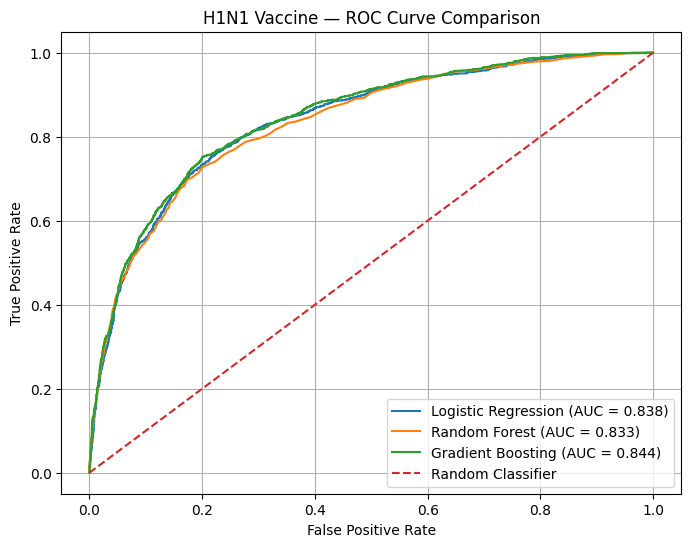

In [79]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# -----------------------------
# H1N1 ROC Curves
# -----------------------------

fpr_lr_h1n1, tpr_lr_h1n1, _ = roc_curve(
    y_h1n1_test,
    h1n1_pred
)

fpr_rf_h1n1, tpr_rf_h1n1, _ = roc_curve(
    y_h1n1_test,
    rf_h1n1_pred
)

fpr_gb_h1n1, tpr_gb_h1n1, _ = roc_curve(
    y_h1n1_test,
    final_gb_h1n1_pred
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr_h1n1,
    tpr_lr_h1n1,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_h1n1_test, h1n1_pred):.3f})"
)

plt.plot(
    fpr_rf_h1n1,
    tpr_rf_h1n1,
    label=f"Random Forest (AUC = {roc_auc_score(y_h1n1_test, rf_h1n1_pred):.3f})"
)

plt.plot(
    fpr_gb_h1n1,
    tpr_gb_h1n1,
    label=f"Gradient Boosting (AUC = {roc_auc_score(y_h1n1_test, final_gb_h1n1_pred):.3f})"
)

# Random classifier reference
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("H1N1 Vaccine — ROC Curve Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [80]:
import pandas as pd

# H1N1 prediction analysis
h1n1_analysis = pd.DataFrame({
    "actual": y_h1n1_test.values,
    "predicted_probability": final_gb_h1n1_pred
})

print(h1n1_analysis.head(20))

print("\nPrediction statistics:")
print(h1n1_analysis["predicted_probability"].describe())

    actual  predicted_probability
0        0               0.022597
1        0               0.736968
2        0               0.030063
3        0               0.114291
4        0               0.099097
5        0               0.539231
6        1               0.879958
7        0               0.058988
8        1               0.085181
9        1               0.402205
10       0               0.009137
11       0               0.056072
12       0               0.071973
13       1               0.176319
14       0               0.080494
15       0               0.010504
16       0               0.273107
17       1               0.606175
18       0               0.074867
19       0               0.034122

Prediction statistics:
count    5342.000000
mean        0.212729
std         0.225317
min         0.008491
25%         0.058418
50%         0.108593
75%         0.290816
max         0.957055
Name: predicted_probability, dtype: float64


In [85]:
from sklearn.metrics import confusion_matrix, classification_report

# Convert probabilities to class predictions
h1n1_pred_class = (final_gb_h1n1_pred >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(
    y_h1n1_test,
    h1n1_pred_class
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_h1n1_test,
        h1n1_pred_class
    )
)

Confusion Matrix:
[[3974  233]
 [ 609  526]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.94      0.90      4207
           1       0.69      0.46      0.56      1135

    accuracy                           0.84      5342
   macro avg       0.78      0.70      0.73      5342
weighted avg       0.83      0.84      0.83      5342



In [86]:
seasonal_analysis = pd.DataFrame({
    "actual": y_seasonal_test.values,
    "predicted_probability": final_gb_seasonal_pred
})

print(seasonal_analysis.head(20))

print("\nPrediction statistics:")
print(
    seasonal_analysis["predicted_probability"].describe()
)

    actual  predicted_probability
0        1               0.418686
1        1               0.823820
2        0               0.048165
3        0               0.224863
4        0               0.247964
5        0               0.323069
6        1               0.964270
7        1               0.890442
8        1               0.366665
9        1               0.935004
10       0               0.025850
11       0               0.143416
12       0               0.199935
13       1               0.347912
14       0               0.131846
15       0               0.053228
16       1               0.962148
17       1               0.546661
18       0               0.089435
19       0               0.034312

Prediction statistics:
count    5342.000000
mean        0.467315
std         0.308235
min         0.007886
25%         0.167720
50%         0.434571
75%         0.773496
max         0.976764
Name: predicted_probability, dtype: float64


In [87]:
seasonal_pred_class = (
    final_gb_seasonal_pred >= 0.5
).astype(int)

cm_seasonal = confusion_matrix(
    y_seasonal_test,
    seasonal_pred_class
)

print("Confusion Matrix:")
print(cm_seasonal)

print("\nClassification Report:")
print(
    classification_report(
        y_seasonal_test,
        seasonal_pred_class
    )
)

Confusion Matrix:
[[2314  540]
 [ 603 1885]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.81      0.80      2854
           1       0.78      0.76      0.77      2488

    accuracy                           0.79      5342
   macro avg       0.79      0.78      0.78      5342
weighted avg       0.79      0.79      0.79      5342

